# Notebook 3: Interpretabilidad del modelo
Modelo analizado: versión con alias `produccion` del Model Registry.
- **Globales:** importancia por permutación, SHAP (beeswarm y barras), dependencia parcial (PDP).
- **Locales:** SHAP waterfall y LIME sobre cuatro casos: fraude detectado, normal correcto, falso positivo y falso negativo.

In [1]:
import os  # variables de entorno y carpetas
import numpy as np  # cálculo numérico
import pandas as pd  # tablas
import matplotlib.pyplot as plt  # gráficas
import mlflow
import mlflow.lightgbm  # cargar modelos LightGBM desde MLflow
import shap  # valores SHAP
from dotenv import load_dotenv  # lee el .env
from mlflow import MlflowClient  # cliente del Model Registry
from lime.lime_tabular import LimeTabularExplainer  # LIME para datos tabulares
from sklearn.inspection import permutation_importance, PartialDependenceDisplay
from sklearn.metrics import average_precision_score

load_dotenv("../.env")  # credenciales de DagsHub
mlflow.set_tracking_uri(os.environ["MLFLOW_TRACKING_URI"])

SEMILLA = 42
OBJETIVO = "isFraud"
FEATURES = [
    "amount", "oldbalanceOrg", "newbalanceOrig", "oldbalanceDest", "newbalanceDest",
    "errorBalanceOrig", "errorBalanceDest", "origenVacio", "destinoVacio",
    "hora_dia", "es_transfer",
]
NOMBRE_MODELO = "fraude-paysim-lgbm"
os.makedirs("../reports/figuras", exist_ok=True)  # aquí se guardan las figuras para el README

modelo = mlflow.lightgbm.load_model(f"models:/{NOMBRE_MODELO}@produccion")  # carga el modelo productivo por su alias
cliente = MlflowClient()
version = cliente.get_model_version_by_alias(NOMBRE_MODELO, "produccion")  # qué versión tiene el alias
umbral = float(cliente.get_run(version.run_id).data.params["umbral_log_odds"])  # umbral guardado en el run de origen
print(f"Modelo versión {version.version} | umbral (log-odds): {umbral:.4f}")

test = pd.read_parquet("../data/processed/full/test.parquet")
X_test, y_test = test[FEATURES], test[OBJETIVO]
puntaje = modelo.predict(X_test, raw_score=True)  # puntaje crudo (log-odds)
pred = (puntaje >= umbral).astype(int)  # decisión final con el umbral guardado
print("Fraudes en test:", int(y_test.sum()),
      "| detectados:", int(((pred == 1) & (y_test == 1)).sum()),
      "| falsos positivos:", int(((pred == 1) & (y_test == 0)).sum()))

Modelo versión 1 | umbral (log-odds): -2.1456
Fraudes en test: 2136 | detectados: 2135 | falsos positivos: 1


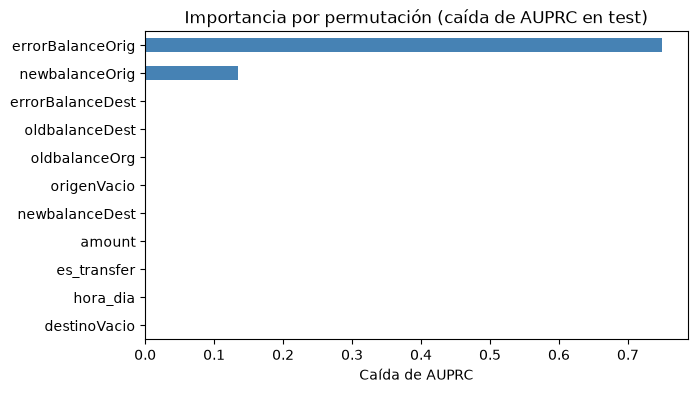

errorBalanceOrig    0.7491
newbalanceOrig      0.1351
errorBalanceDest    0.0007
oldbalanceDest      0.0004
oldbalanceOrg       0.0002
origenVacio         0.0002
newbalanceDest      0.0002
amount              0.0002
es_transfer         0.0001
hora_dia            0.0001
destinoVacio        0.0000
dtype: float64


In [2]:
def scorer_ap(est, X, y):
    """Puntúa un modelo con AUPRC sobre el puntaje crudo.

    Args:
        est: modelo entrenado.
        X: variables.
        y: etiquetas reales.

    Returns:
        AUPRC (float).
    """
    return average_precision_score(y, est.predict(X, raw_score=True))


res = permutation_importance(
    modelo, X_test, y_test, scoring=scorer_ap,  # métrica con la que se mide la caída
    n_repeats=3, random_state=SEMILLA, n_jobs=1,  # 3 mezclas por variable
)
imp_perm = pd.Series(res.importances_mean, index=FEATURES).sort_values()  # caída media de AUPRC por variable

fig, ax = plt.subplots(figsize=(7, 4))
imp_perm.plot(kind="barh", ax=ax, color="steelblue")
ax.set_title("Importancia por permutación (caída de AUPRC en test)")
ax.set_xlabel("Caída de AUPRC")
fig.savefig("../reports/figuras/importancia_permutacion.png", dpi=150, bbox_inches="tight")
plt.show()
print(imp_perm.sort_values(ascending=False).round(4))

Forma de los valores SHAP: (6136, 11)


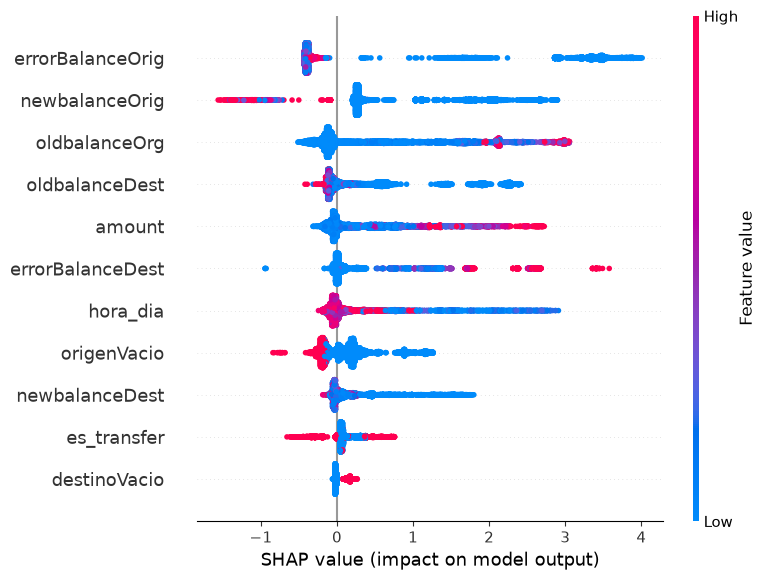

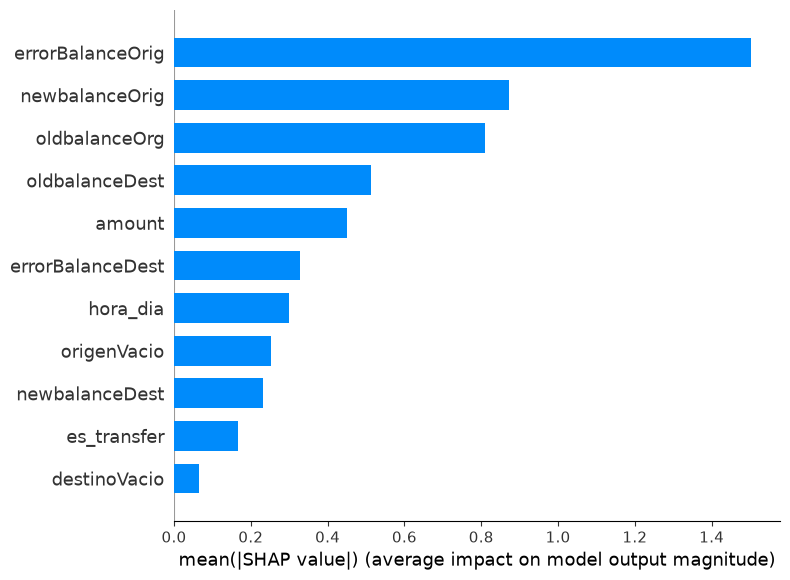

errorBalanceOrig    1.503
newbalanceOrig      0.873
oldbalanceOrg       0.810
oldbalanceDest      0.512
amount              0.451
errorBalanceDest    0.328
hora_dia            0.298
origenVacio         0.252
newbalanceDest      0.232
es_transfer         0.168
destinoVacio        0.064
dtype: float64


In [3]:
rng = np.random.default_rng(SEMILLA)
idx_fraude = np.where(y_test.values == 1)[0]  # posiciones de todos los fraudes
idx_normal = np.where(y_test.values == 0)[0]  # posiciones de los normales
idx_muestra = np.concatenate([idx_fraude, rng.choice(idx_normal, size=4000, replace=False)])  # todos los fraudes + 4,000 normales
X_m = X_test.iloc[idx_muestra]  # muestra para SHAP

explicador = shap.TreeExplainer(modelo)  # explicador exacto para modelos de árboles


def explicar(X):
    """Calcula los valores SHAP de un DataFrame y los devuelve como objeto Explanation.

    Args:
        X: DataFrame con las variables del modelo.

    Returns:
        shap.Explanation con valores SHAP en la escala de log-odds de la clase fraude.
    """
    e = explicador(X)
    vals, base = e.values, e.base_values
    if vals.ndim == 3:  # algunas versiones devuelven una matriz por clase
        vals, base = vals[:, :, 1], base[:, 1]  # nos quedamos con la clase fraude
    return shap.Explanation(values=vals, base_values=base, data=X.values, feature_names=list(X.columns))


exp_m = explicar(X_m)
print("Forma de los valores SHAP:", exp_m.values.shape)

shap.summary_plot(exp_m.values, X_m, show=False)  # beeswarm: efecto y dirección de cada variable
plt.gcf().savefig("../reports/figuras/shap_beeswarm.png", dpi=150, bbox_inches="tight")
plt.show()

shap.summary_plot(exp_m.values, X_m, plot_type="bar", show=False)  # importancia media absoluta
plt.gcf().savefig("../reports/figuras/shap_barras.png", dpi=150, bbox_inches="tight")
plt.show()

imp_shap = pd.Series(np.abs(exp_m.values).mean(axis=0), index=FEATURES).sort_values(ascending=False)
print(imp_shap.round(3))

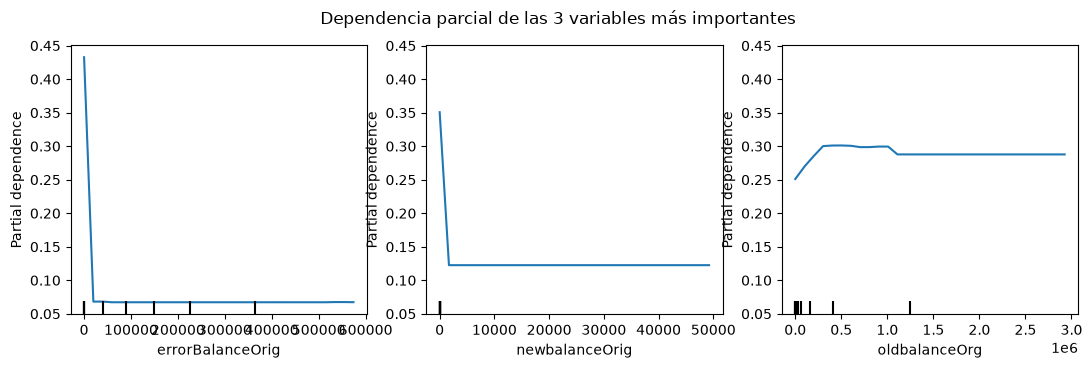

Variables graficadas: ['errorBalanceOrig', 'newbalanceOrig', 'oldbalanceOrg']


In [4]:
top3 = list(imp_shap.index[:3])  # las 3 variables más importantes según SHAP

fig, ejes = plt.subplots(1, 3, figsize=(13, 3.5))
PartialDependenceDisplay.from_estimator(
    modelo, X_m, features=top3,  # variables a analizar
    kind="average",  # efecto promedio
    grid_resolution=30,  # 30 puntos por variable
    ax=ejes,
)
fig.suptitle("Dependencia parcial de las 3 variables más importantes")
fig.savefig("../reports/figuras/pdp_top3.png", dpi=150, bbox_inches="tight")
plt.show()
print("Variables graficadas:", top3)

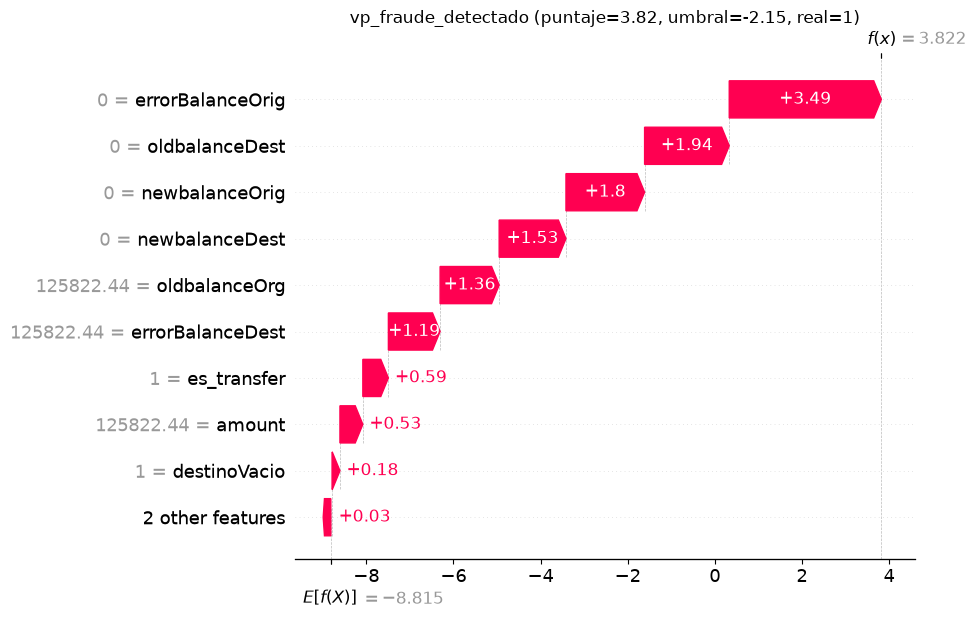

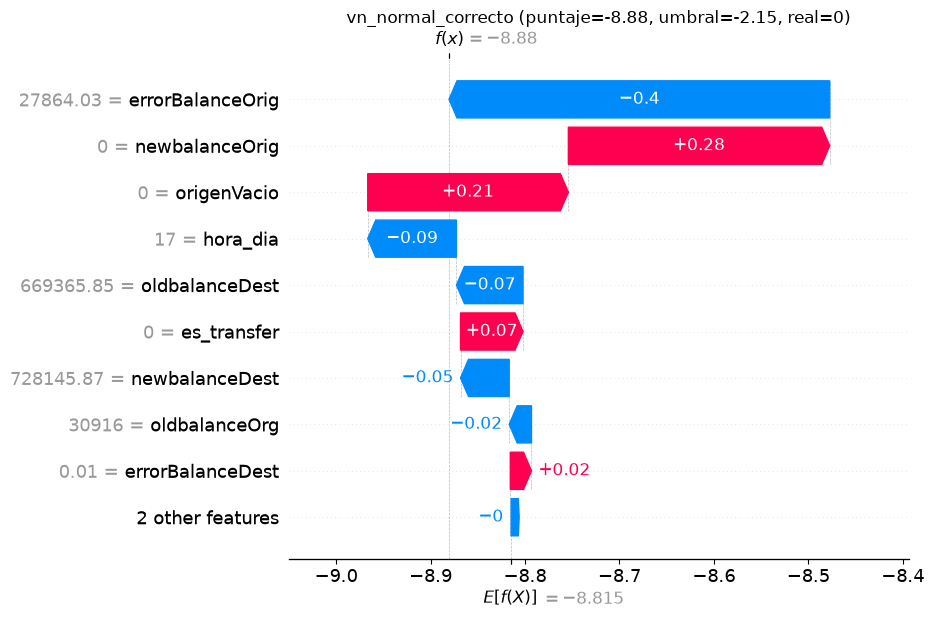

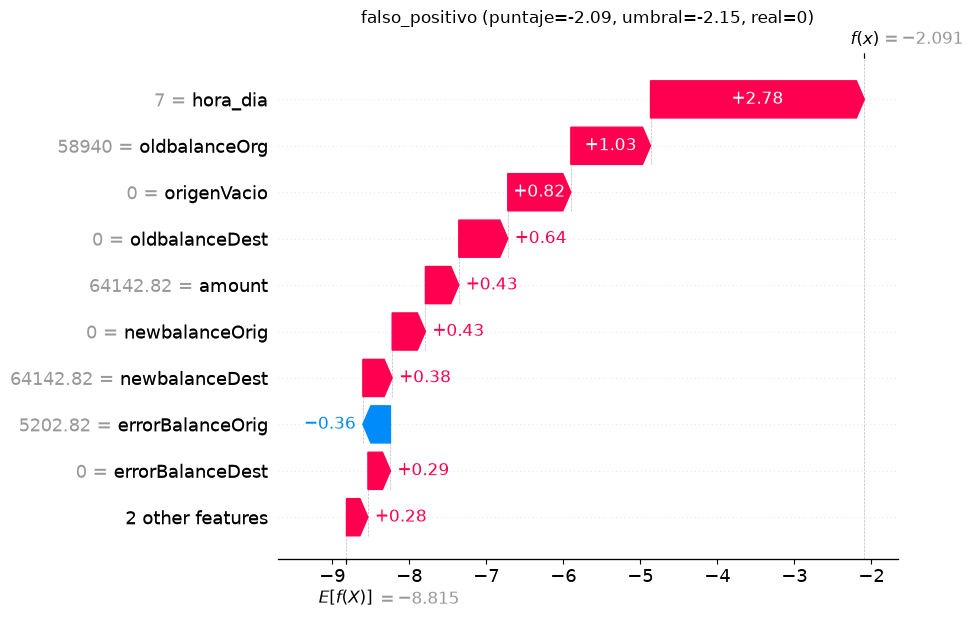

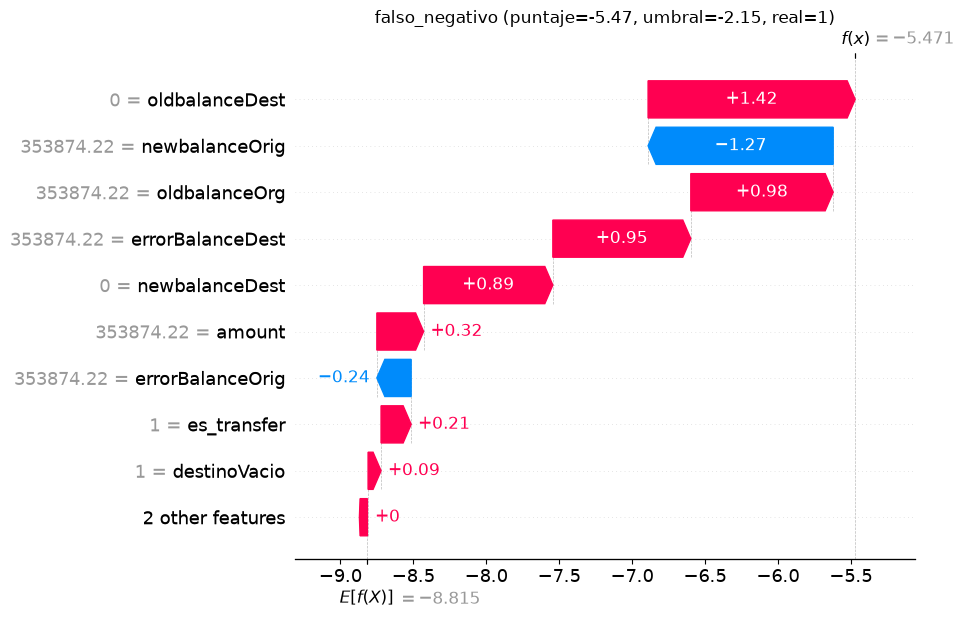

In [5]:
casos = {  # nombre: posición dentro de test
    "vp_fraude_detectado": np.where((y_test.values == 1) & (pred == 1))[0][0],  # primer fraude detectado
    "vn_normal_correcto": np.where((y_test.values == 0) & (pred == 0))[0][0],  # primer normal bien clasificado
}
fp = np.where((y_test.values == 0) & (pred == 1))[0]  # falsos positivos
fn = np.where((y_test.values == 1) & (pred == 0))[0]  # falsos negativos
if len(fp):
    casos["falso_positivo"] = fp[0]
if len(fn):
    casos["falso_negativo"] = fn[0]

for nombre, i in casos.items():
    fila = X_test.iloc[[i]]  # [[i]] mantiene el formato de DataFrame
    e = explicar(fila)
    shap.plots.waterfall(e[0], show=False)  # cascada de contribuciones de esta predicción
    plt.title(f"{nombre} (puntaje={puntaje[i]:.2f}, umbral={umbral:.2f}, real={int(y_test.iloc[i])})")
    plt.gcf().savefig(f"../reports/figuras/shap_waterfall_{nombre}.png", dpi=150, bbox_inches="tight")
    plt.show()

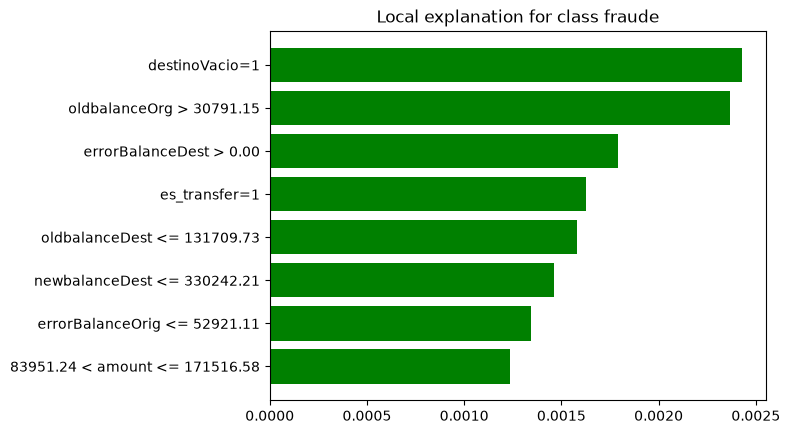

vp_fraude_detectado [('destinoVacio=1', 0.002), ('oldbalanceOrg > 30791.15', 0.002), ('errorBalanceDest > 0.00', 0.002)]


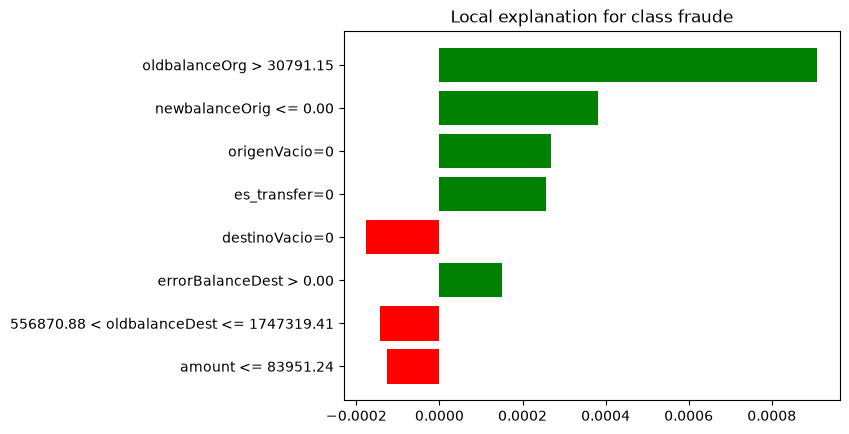

vn_normal_correcto [('oldbalanceOrg > 30791.15', 0.001), ('newbalanceOrig <= 0.00', 0.0), ('origenVacio=0', 0.0)]


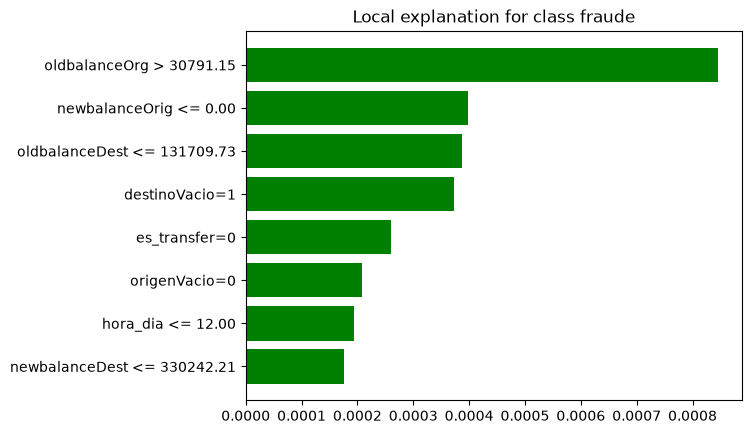

falso_positivo [('oldbalanceOrg > 30791.15', 0.001), ('newbalanceOrig <= 0.00', 0.0), ('oldbalanceDest <= 131709.73', 0.0)]


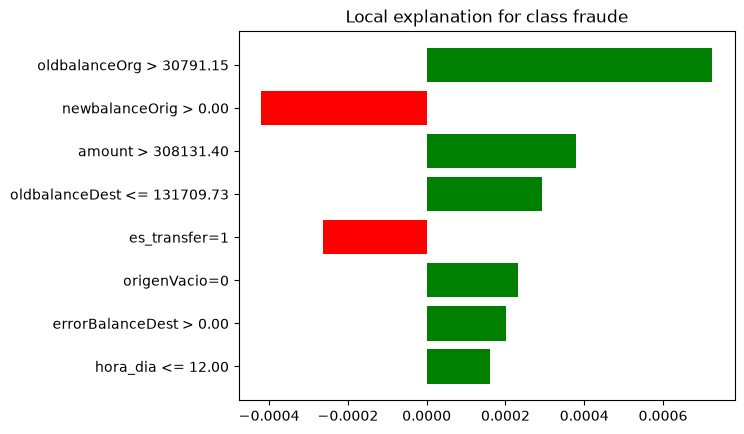

falso_negativo [('oldbalanceOrg > 30791.15', 0.001), ('newbalanceOrig > 0.00', -0.0), ('amount > 308131.40', 0.0)]


In [6]:
train = pd.read_parquet("../data/processed/full/train.parquet", columns=FEATURES)  # solo las columnas necesarias
fondo = train.sample(20000, random_state=SEMILLA)  # datos de referencia para las perturbaciones de LIME
cat_idx = [FEATURES.index(c) for c in ["origenVacio", "destinoVacio", "es_transfer"]]  # variables binarias

explicador_lime = LimeTabularExplainer(
    fondo.values,  # distribución de referencia
    feature_names=FEATURES,
    class_names=["normal", "fraude"],
    categorical_features=cat_idx,  # se tratan como categorías, no como continuas
    mode="classification",
    discretize_continuous=True,  # convierte variables continuas en rangos legibles
    random_state=SEMILLA,
)


def predecir_proba(a):
    """Devuelve probabilidades por clase a partir de un arreglo de numpy (formato que pide LIME)."""
    return modelo.predict_proba(pd.DataFrame(a, columns=FEATURES))


for nombre, i in casos.items():
    e = explicador_lime.explain_instance(
        X_test.iloc[i].values,  # la transacción a explicar
        predecir_proba,
        num_features=8,  # las 8 variables más influyentes
        num_samples=5000,  # perturbaciones generadas alrededor del caso
    )
    fig = e.as_pyplot_figure()
    fig.savefig(f"../reports/figuras/lime_{nombre}.png", dpi=150, bbox_inches="tight")
    plt.show()
    print(nombre, [(a, round(b, 3)) for a, b in e.as_list()[:3]])

## Conclusiones de interpretabilidad
**Globales.** La importancia por permutación y SHAP coinciden en las dos primeras variables: `errorBalanceOrig` (caída de AUPRC 0.749; SHAP medio 1.50) y `newbalanceOrig` (0.135; 0.87). La permutación asigna casi cero al resto (≤ 0.0007) porque son redundantes: al mezclar una, las otras compensan. SHAP reparte la contribución entre variables correlacionadas (`oldbalanceOrg` 0.81, `oldbalanceDest` 0.51, `amount` 0.45). El PDP muestra un escalón en 0 para `errorBalanceOrig` y `newbalanceOrig`: el modelo se comporta casi como una regla sobre la coherencia contable del saldo de origen.
**Locales.**
- *Fraude detectado:* puntaje 3.82 (valor base −8.82). Suman `errorBalanceOrig = 0` (+3.49), `oldbalanceDest = 0` (+1.94), `newbalanceOrig = 0` (+1.80) y `newbalanceDest = 0` (+1.53): la cuenta se vacía y el destino estaba vacío.
- *Falso positivo:* puntaje −2.09, apenas 0.06 sobre el umbral (−2.15). Lo empuja sobre todo `hora_dia = 7` (+2.78), una variable débil, más `oldbalanceOrg` (+1.03). Es un caso fronterizo.
- *Falso negativo:* puntaje −5.47. Es un fraude cuyo saldo de origen no se debitó (`newbalanceOrig`, `oldbalanceOrg` y `amount` valen 353,874.22), así que no muestra la firma dominante.
**LIME.** Los pesos son muy pequeños (~10⁻³) porque el modelo es muy seguro. Su discretización por cuantiles agrupa el cero de `errorBalanceOrig` en el rango "≤ 52,921" y por eso no lo destaca, mientras que SHAP lo pone primero. Usamos SHAP como técnica local principal y LIME como contraste.
**Limitaciones.** La señal dominante es un patrón del simulador PaySim, y usa saldos posteriores a la transacción. El rendimiento perfecto no es extrapolable a datos reales. `hora_dia` es frágil: refleja los ciclos de volumen del simulador.